In [98]:
#hello
import pandas as pd
data = pd.read_csv("data/AmesHousing.csv", sep ='\t')
display(data.head())

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [ ]:
# *the feature 'Fence' (fence quality) should be devided into 2, because it's attributes are: 
#        - GdPrv	Good Privacy
#        - MnPrv	Minimum Privacy
#        - GdWo	Good Wood
#        - MnWw	Minimum Wood/Wire
#        - NA	No Fence
# *there should be: 
#  Fence Pcy: fence privacy
#        - GdPrv	Good Privacy
#        - MnPrv	Minimum Privacy
#  and \
#   Fence Matl: fence material
#        - GdWo	Good Wood
#        - MnWw	Minimum Wood/Wire
#        - NA	No Fence


## Numerical Features


In [106]:
#  to look at value distributions I chose to create a box plot
#  # numerical features except Order because it's just a kind of ID and PID:
# Lot Frontage
# Lot Area
# Overall Qual
# Overall Cond
# Year Built
# Year Remod/Add
# Mas Vnr Area
# BsmtFin SF 1
# BsmtFin SF 2
# Bsmt Unf SF
# Total Bsmt SF  
# 1st Flr SF
# 2nd Flr SF
# Low Qual Fin SF
# # is there a value that holds the whole buildings SF? bsmt, 1st and 2nd floor have them separately then low qual. Could it be above gr living area or is that more than just the building, does it include the garden too for ex?
# # the answer: Gr Liv Area include 1st, 2nd floor, low qual. It does not include the garden but it does not include the basement, garage and porches either. So a TotHouse SF might be a good idea. I for one would like to have one. 
# Gr Liv Area
# Bsmt Full Bath
# Bsmt Half Bath
# Full Bath
# Half Bath
# Bedroom --> Bedroom AbvGr (in CSV)
# Kitchen --> Kitchen AbvGr
# TotRmsAbvGrd --> TotRms AbvGrd
# Fireplaces
# Garage Year Blt --> Garage Yr Blt
# Garage Cars
# Garage Area
# Wood Deck SF
# Open Porch SF
# Enclosed Porch
# 3-Ssn Porch --> 3Ssn Porch
# Screen Porch
# Pool Area
# Misc Val ??
# Mo Sold --> for these 2 maybe a count plot

# Yr Sold
# SalePrice

In [ ]:
data.describe().T #just found this ina quiz on Geeks for Geeks - this would have been easier :) but at least I looked through all features thoroughly

,count,mean,std,min,25%,50%,75%,max
Order,2930.0,1.465500e+03,8.459625e+02,1.0,7.332500e+02,1465.5,2.197750e+03,2.930000e+03
PID,2930.0,7.144645e+08,1.887308e+08,526301100.0,5.284770e+08,535453620.0,9.071811e+08,1.007100e+09
MS SubClass,2930.0,5.738737e+01,4.263802e+01,20.0,2.000000e+01,50.0,7.000000e+01,1.900000e+02
Lot Frontage,2440.0,6.922459e+01,2.336533e+01,21.0,5.800000e+01,68.0,8.000000e+01,3.130000e+02
Lot Area,2930.0,1.014792e+04,7.880018e+03,1300.0,7.440250e+03,9436.5,1.155525e+04,2.152450e+05
Overall Qual,2930.0,6.094881e+00,1.411026e+00,1.0,5.000000e+00,6.0,7.000000e+00,1.000000e+01
Overall Cond,2930.0,5.563140e+00,1.111537e+00,1.0,5.000000e+00,5.0,6.000000e+00,9.000000e+00
Year Built,2930.0,1.971356e+03,3.024536e+01,1872.0,1.954000e+03,1973.0,2.001000e+03,2.010000e+03
Year Remod/Add,2930.0,1.984267e+03,2.086029e+01,1950.0,1.965000e+03,1993.0,2.004000e+03,2.010000e+03
Mas Vnr Area,2907.0,1.018968e+02,1.791126e+02,0.0,0.000000e+00,0.0,1.640000e+02,1.600000e+03


## Box Plot
### Relationship between features

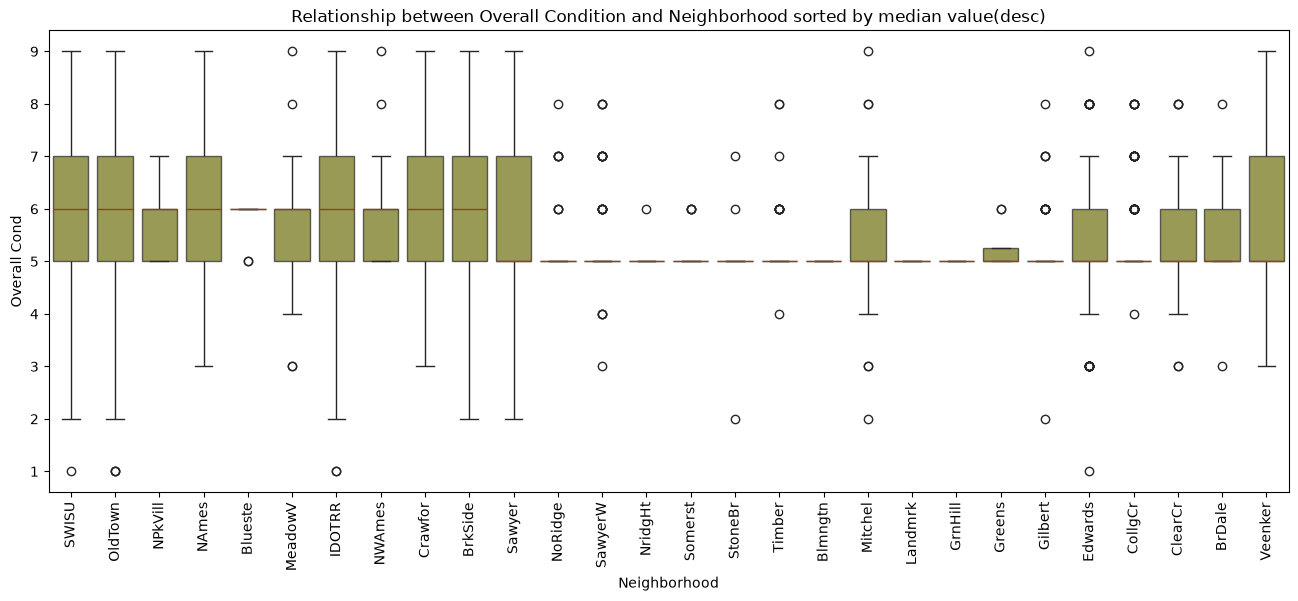

In [152]:

import matplotlib.pyplot as plt
import seaborn as sns
#for my box plot the first question that came to mind: do I look at this data from the perspective of the seller or the buyer?
# Keep it neutral so both can use it. 
#What I would start to wonder about as a buyer and seller is how the Overall Cond and?or Overall Qual of the dwelling
# (is a building (or part of one) where people live. It’s a general word that covers houses, apartments, townhouses, duplexes, and so on.) 
# in Ames city devided into Neighborhood
order = data.groupby('Neighborhood')['Overall Cond'].median().sort_values(ascending = False).index
plt.figure(figsize = (16,6))
sns.boxplot(x = 'Neighborhood', y = 'Overall Cond', data = data, order= order,medianprops = {'color': 'saddlebrown'}, color = 'olive', boxprops = {'alpha': 0.7})
plt.xticks(rotation = 90)
plt.title('Relationship between Overall Condition and Neighborhood sorted by median value(desc)')
plt.show()
#Why don't the medians appear in every box plot? 
#Answer it falls on Q1 or Q3, or both when it's flat. I will add a brown color to the median line so I can see on which Quartile it falls 
# The dots, what are they? Answer: Outliers. 'Individual points beyond the whiskers represents outliers.' - from Geeks for Geeks
# Maybe I should sort the boxes after the median in descending order - > i will use the groupby function from pandas

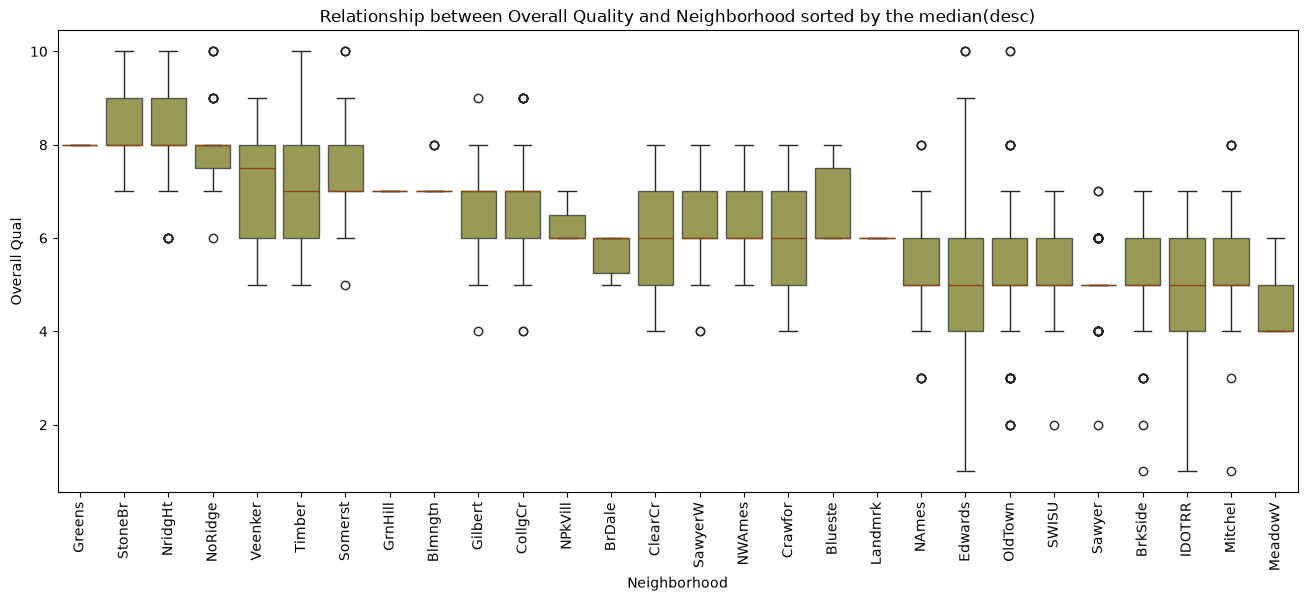

In [153]:
order2 = data.groupby('Neighborhood')['Overall Qual'].median().sort_values(ascending = False).index
plt.figure(figsize = (16,6))
sns.boxplot(x = 'Neighborhood', y = 'Overall Qual', data = data, order = order2, medianprops = {'color': 'saddlebrown', 'alpha': 1}, color = 'olive' ,boxprops = { 'alpha': 0.7})
plt.xticks(rotation = 90)
plt.title('Relationship between Overall Quality and Neighborhood sorted by the median(desc)')
plt.show()
# overall Cond is 5 on avg so the bars don't look that different, but Overall Qual is more variable 

## Violin Plot
### Relationship between features
*holds more information about the distribution of data points*

As a comparison I thought I'd create a violing plot next, as it is similar to the box plot but holds more information about the distribution of data points as I understand. (density estimate around the y-axis), but I don't understand why it's mirrored 'The density is mirrored and flipped over, and the resulting shape is filled in, creating an image resembling a violin.' - from GfG. 

The box plot shows outliers more visibly.

Let's do a violing plot for Neighborhood and Overall Qual as a comparison and then do one for Neighborhood and Price.

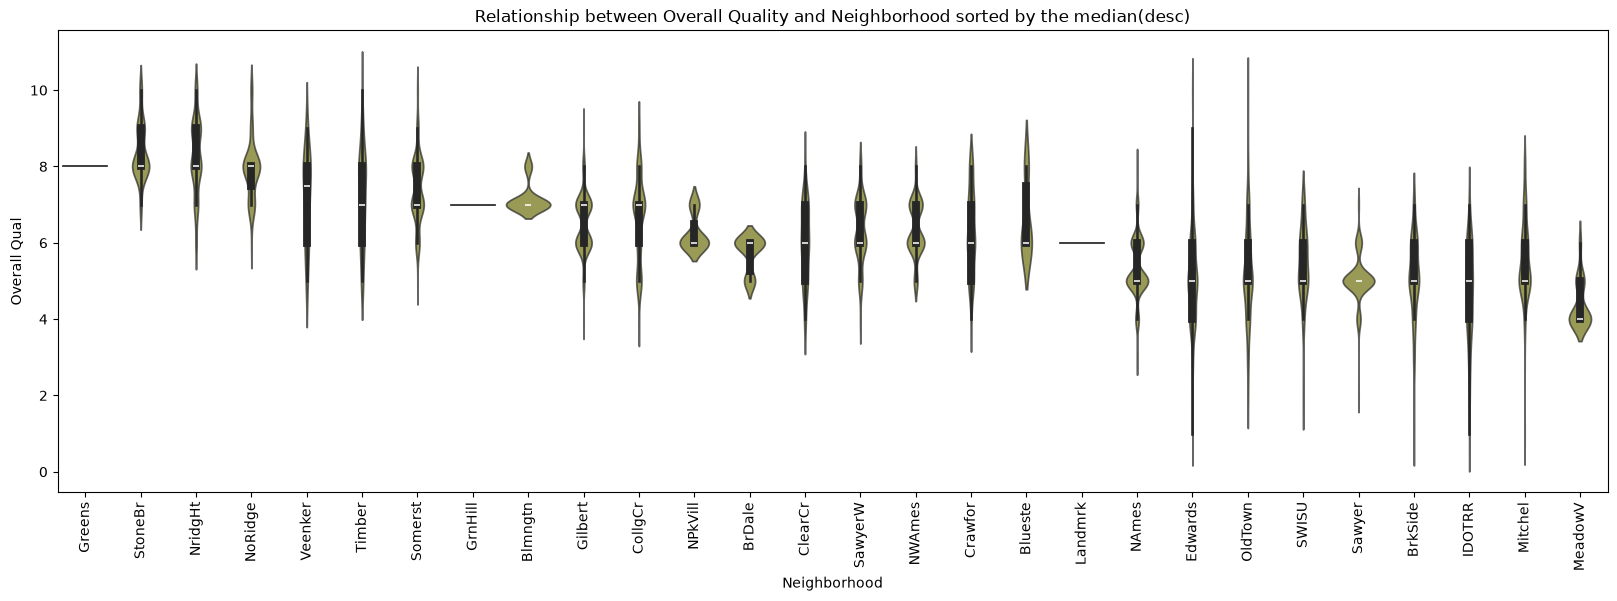

In [154]:

plt.figure(figsize = (20,6))
sns.violinplot(x = 'Neighborhood', y = 'Overall Qual', data = data, order = order2, color = 'olive', alpha = 0.7)
plt.xticks(rotation = 90)
plt.title('Relationship between Overall Quality and Neighborhood sorted by the median(desc)')
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

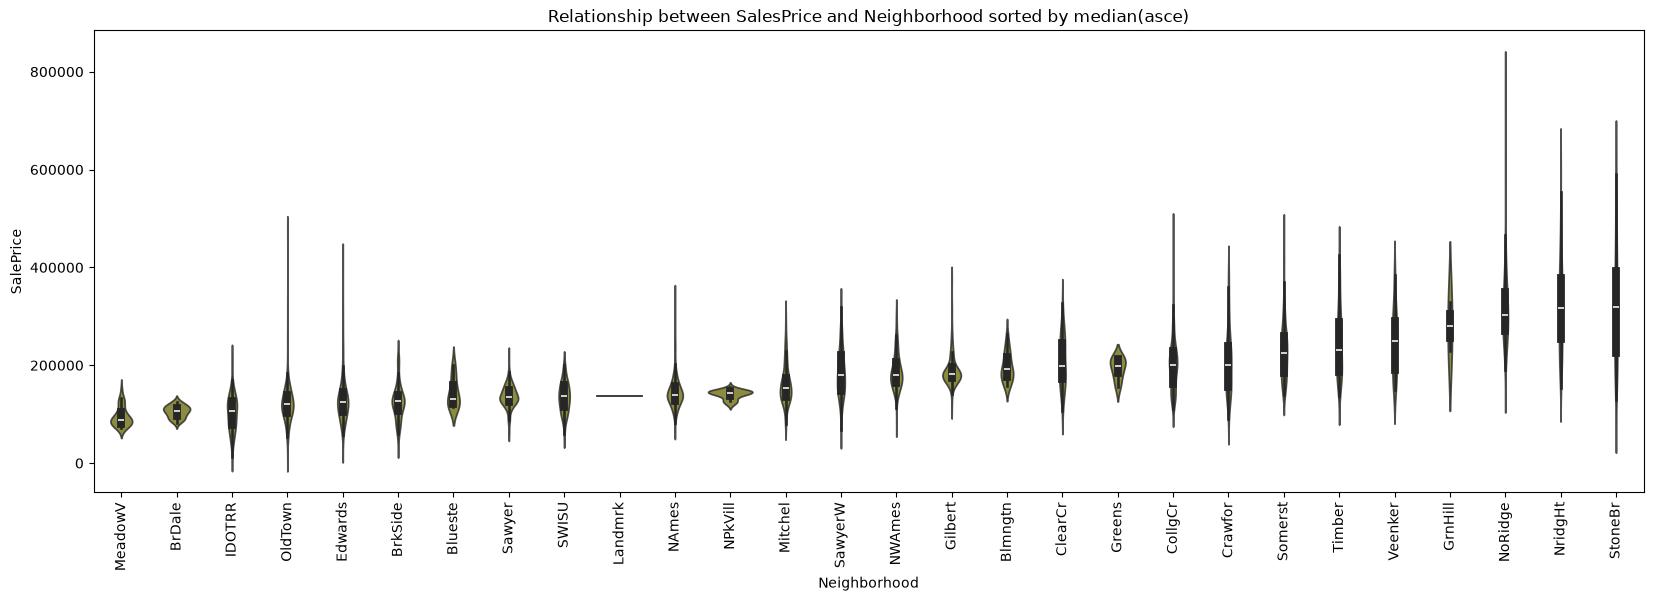

In [156]:
order3 = data.groupby('Neighborhood')['SalePrice'].median().sort_values().index
plt.figure(figsize = (20,6))
sns.violinplot(x = 'Neighborhood', y = 'SalePrice', data = data, order = order3, color = 'olive', alpha = 0.8)
plt.xticks(rotation = 90)
plt.title('Relationship between SalesPrice and Neighborhood sorted by median(asce)')
plt.show

In the Neighborhoods with the highest prices there are the most Outliers, let's make a 
## box plot to see the Outliers more clearly

<function matplotlib.pyplot.show(close=None, block=None)>

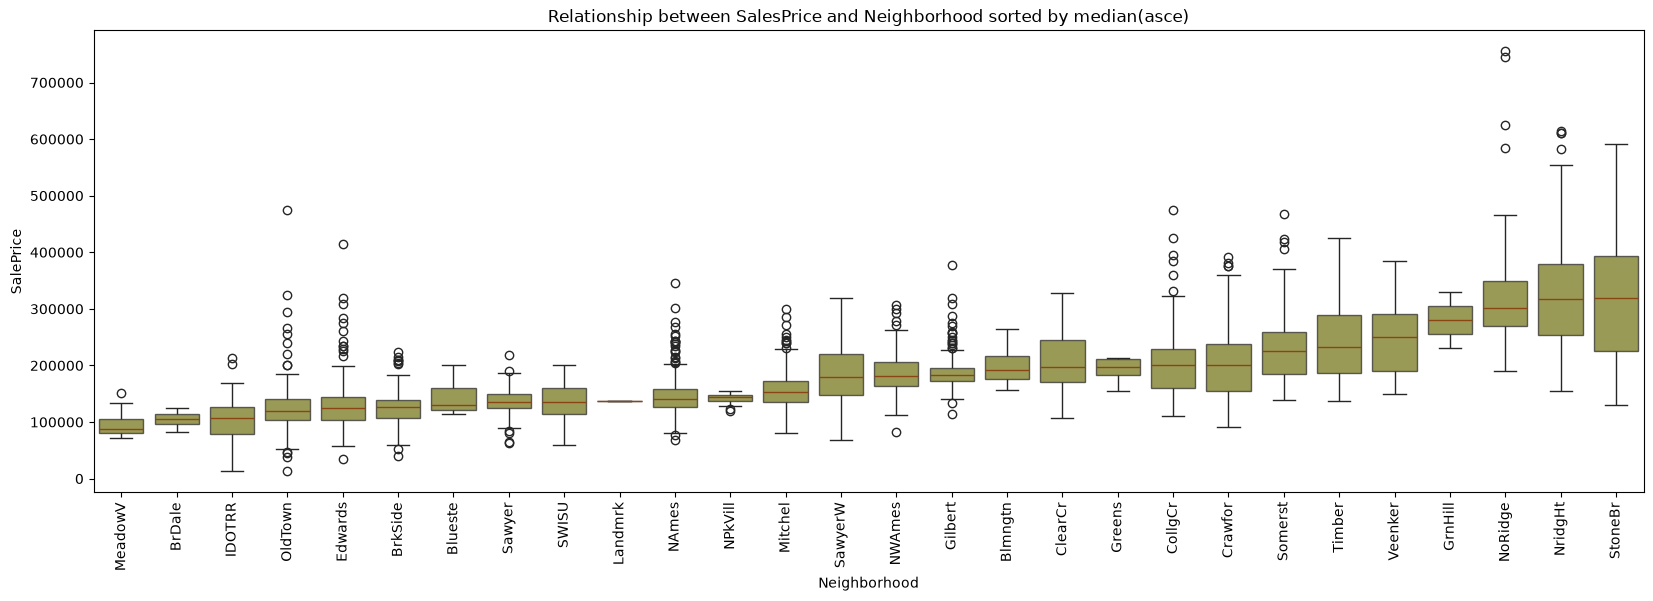

In [157]:
plt.figure(figsize = (20,6))
sns.boxplot(x = 'Neighborhood', y = 'SalePrice',data = data, order= order3, color = 'olive', boxprops = {'alpha': 0.7}, medianprops = {'color': 'saddlebrown'})
plt.xticks(rotation = 90)
plt.title('Relationship between SalesPrice and Neighborhood sorted by median(asce)')
plt.show

## Box Plots sorted after nr of outliers 

 Actually they don't truly show up as having as many outliers as I thought, only for NoRidge some at the top, and for NridgHt at the top. For StoneBr nothing at all it's just inside of the maximum and minimum. A lot more outliers are present in **OldTown, Edwards, NAmes, Mitchel, and Gilbert**. Maybe I can sort it after outliers, let's see if I got the Top 5 right.\
 \
I will do this using the IQR method from Geeks for Geeks. There percentile is used from the numpy library to set the quartile percentages, but after more research with Claude suggested that that one does not handle the NaN values, only nanpercentile does and quantile from the pandas library. But I checked in Stefi's missing value results and Sales Price does not have any missing values so using the np.percentile is safe in this case. Although the quantile is more effitient (it uses numpy in the backround wth a line something method) and it does not have a 1-100 range it only has 0-1 

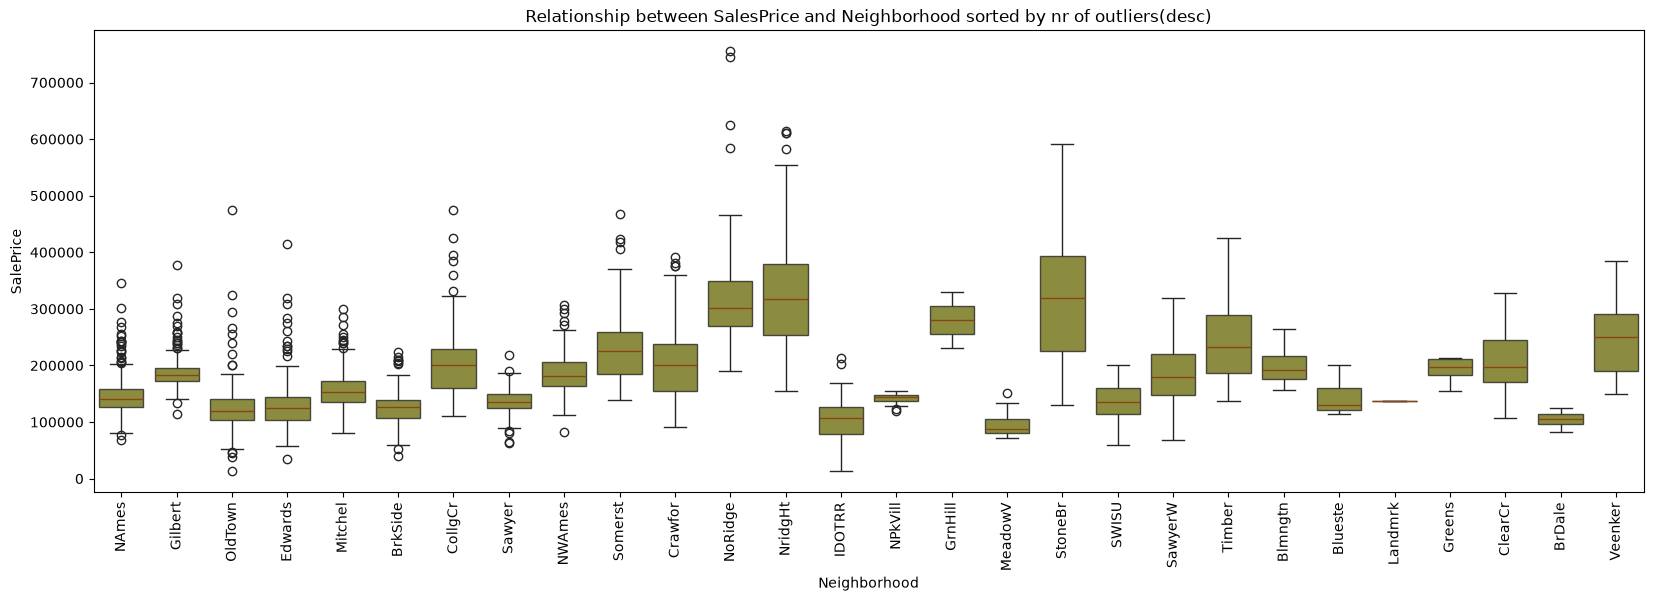

In [158]:
import numpy as np
def outliers_count(s):
    Q1 = np.percentile(s, 25, method= 'midpoint')
    Q3 = np.percentile(s, 75, method = 'midpoint')
    IQR = Q3 - Q1
    upper = Q3 + 1.5 * IQR
    lower = Q1 - 1.5 * IQR
    count = sum((s < lower) | (s > upper)) #apperaently on series I can't use 'or' like I would normally in python because the TRueness of a whole series can not be 
    # determined so '|' and '&' are used for elementwise logical operations
    # !!! don't forget the paranthesees '(s < lower | s > upper)' for each like I did, because it's going to combine prices with a single true/false val instead of two true/false series
    return count
order_outliers = data.groupby('Neighborhood')['SalePrice'].apply(outliers_count).sort_values(ascending = False).index
plt.figure(figsize = (20, 6))
sns.boxplot(x = 'Neighborhood', y = 'SalePrice', data = data, order = order_outliers, color = 'olive', boxprops = {'alpha': 0.8}, medianprops = {'color': 'saddlebrown'})
plt.xticks(rotation = 90)
plt.title('Relationship between SalesPrice and Neighborhood sorted by nr of outliers(desc)')
plt.show()

## Number of outliers in each Neighborhood

In [119]:
#I did get the Top 5 right, did not put them in order before
#  let's print how many there actually are in each NH
counted_outliers = data.groupby('Neighborhood')['SalePrice'].apply(outliers_count).sort_values(ascending = False)
print(counted_outliers)
# the next step would be removing them

Neighborhood
NAmes      22
Gilbert    19
OldTown    13
Edwards    13
Mitchel    10
BrkSide     9
CollgCr     6
Sawyer      6
NWAmes      6
Somerst     5
Crawfor     4
NoRidge     4
NridgHt     4
IDOTRR      2
NPkVill     2
GrnHill     2
MeadowV     1
StoneBr     0
SWISU       0
SawyerW     0
Timber      0
Blmngtn     0
Blueste     0
Landmrk     0
Greens      0
ClearCr     0
BrDale      0
Veenker     0
Name: SalePrice, dtype: int64


## Multivariate Analysis

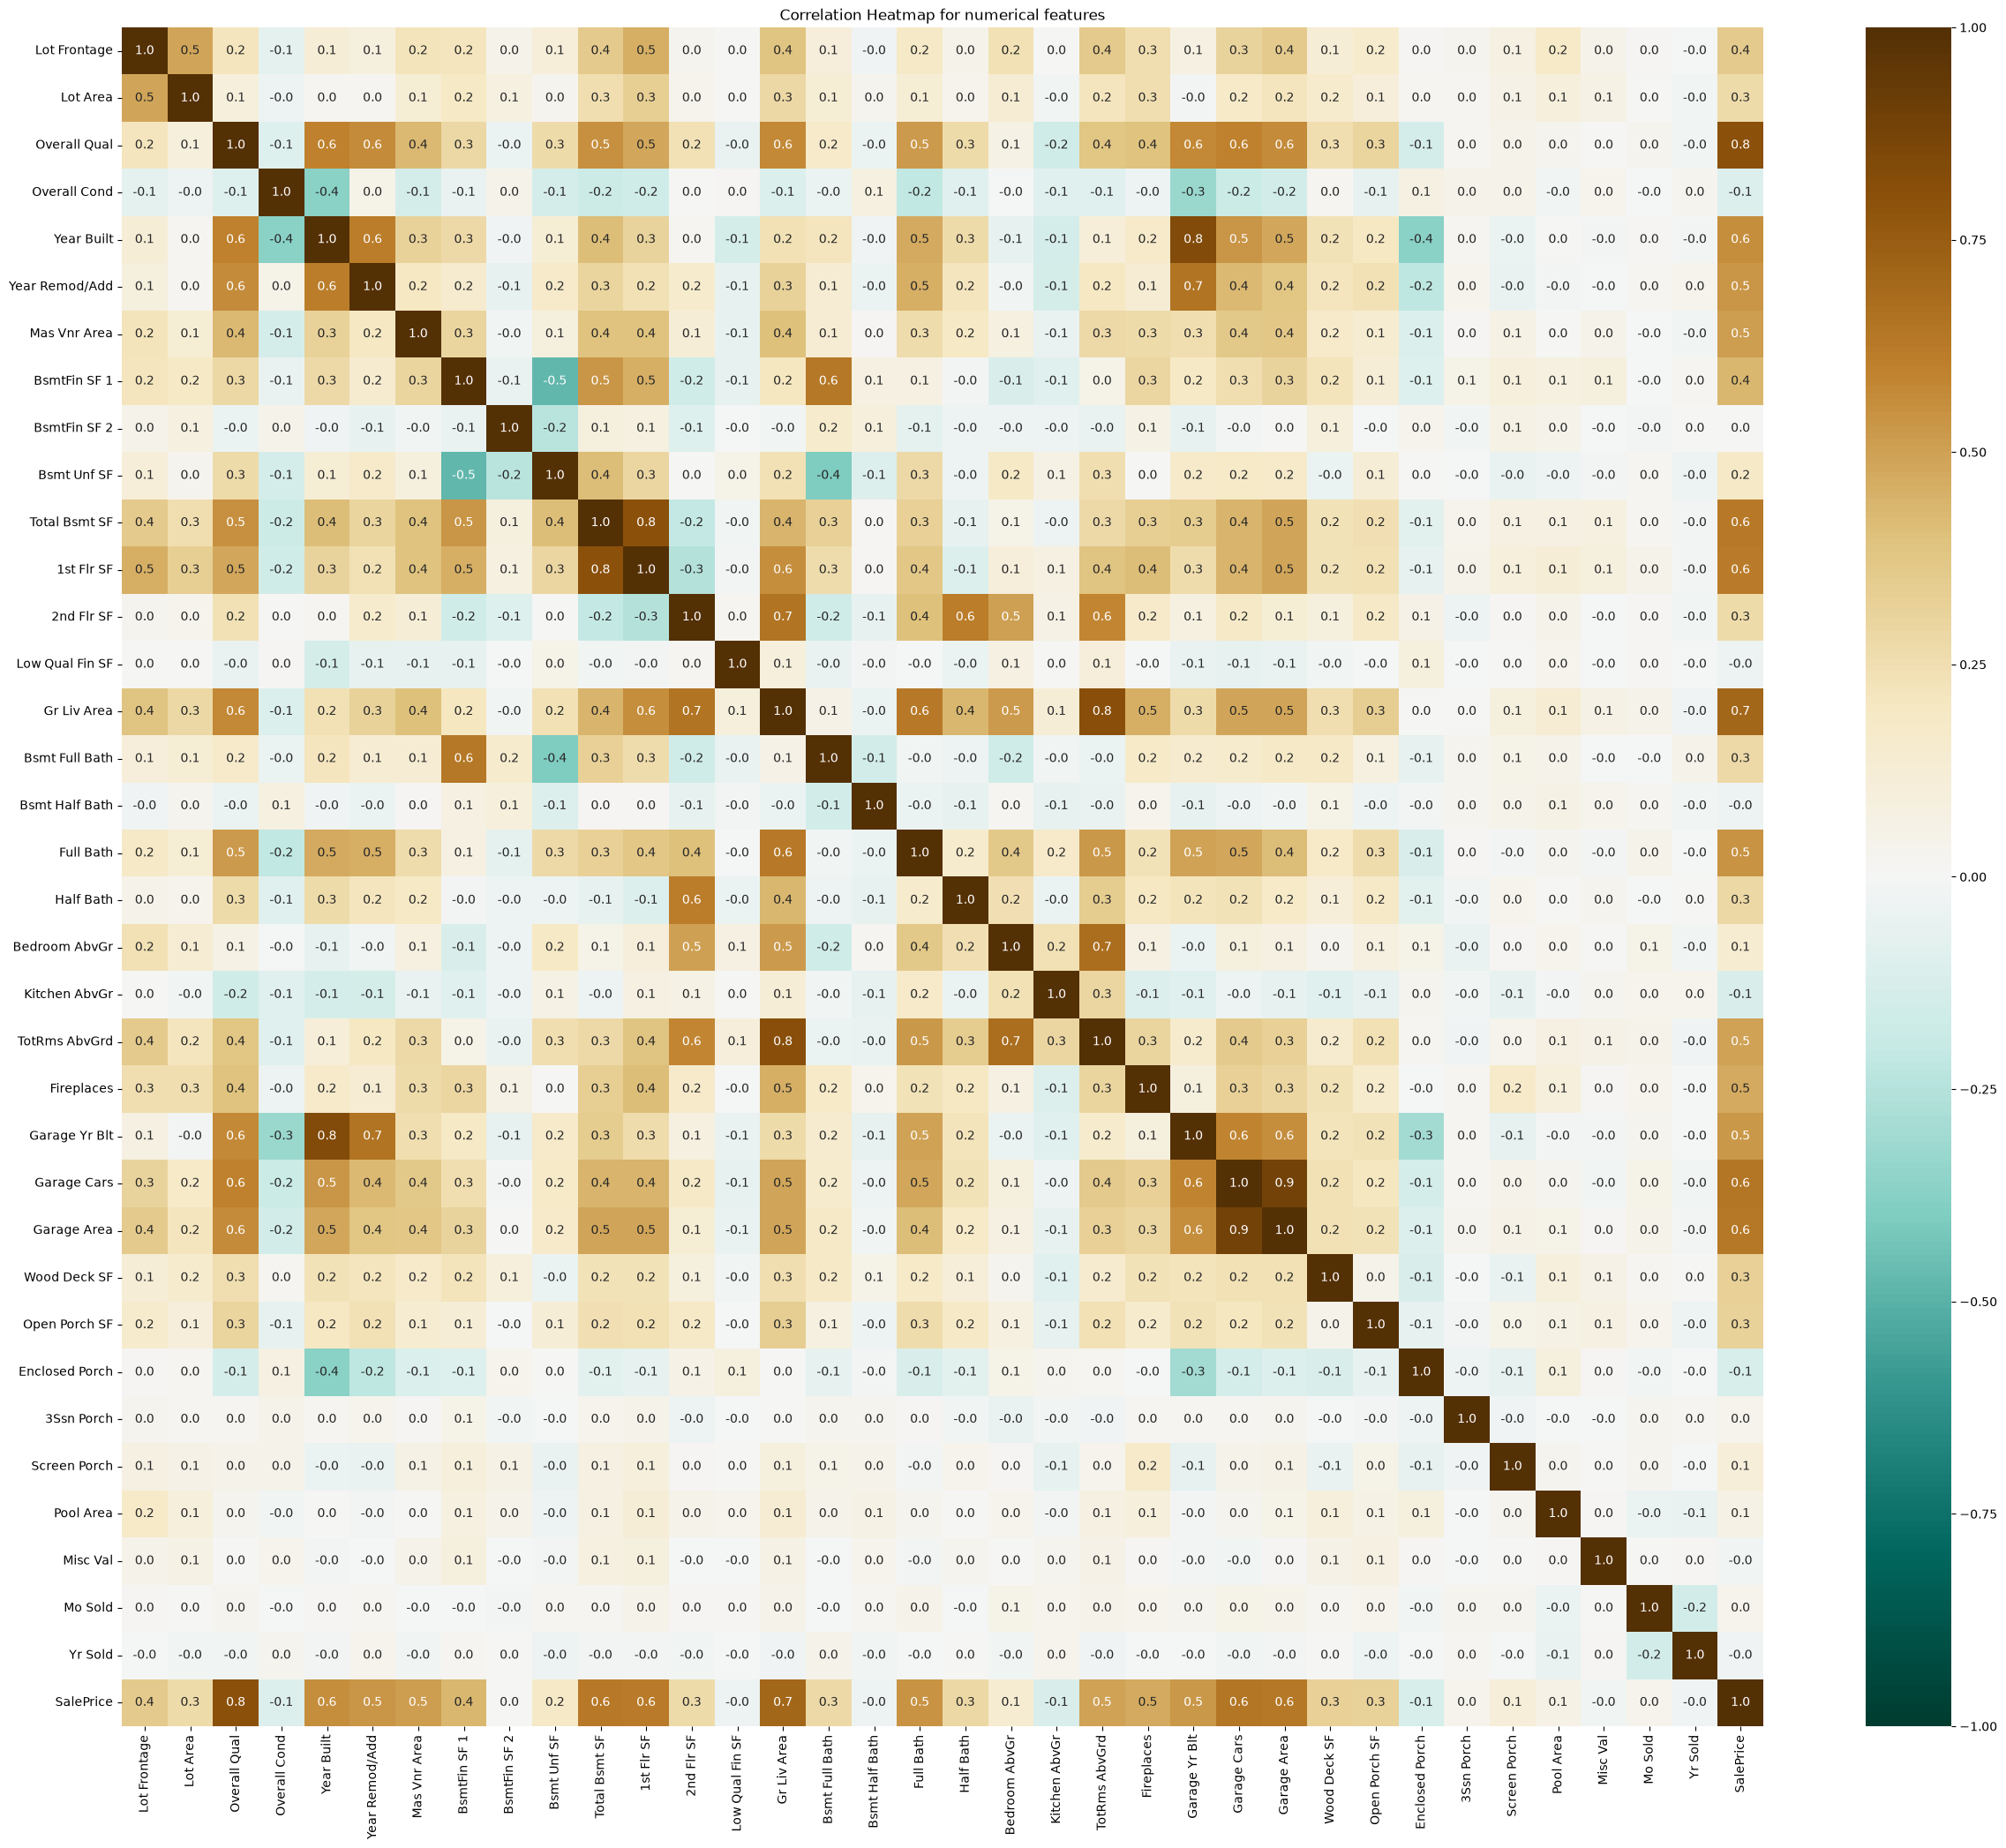

In [163]:
# now let's do a correlation heatmap
plt.figure(figsize = (30,25))
corr = data.drop(columns = ['Order', 'PID', 'MS SubClass']).corr(numeric_only = True)
# .1f stands for only 1 decimal after the . and  vmin = -1, vmax = 1 to have 0 as the neutral white color not blue as it was before, coolwarm is a diverging color map which is good for numerical features and this -1,1 range
sns.heatmap(corr, annot = True, fmt = '.1f', cmap = 'BrBG_r', vmin = -1, vmax = 1) #it only works on numeric features as I jjust found out why it cracked 
# and i don't need Order, PID and MS SubClass (cause there the numbers just correspond to a name)
plt.title('Correlation Heatmap for numerical features')
plt.show()

- garage Cars(area in size of car) and garage Area correlate with each other at 0.9 but that is just because they calculate almost the same thing 
- just as Total Bsmt SF and 1st Flr SF so those corresponding at 0.8 is not important
- Yr Built and Gr Year builr at 0.8 also not of interest
- totrooms above Gr and Gr Liv Area are also too similar to be of interest
- however SalesPrice and Overall Qual at 0.8 is a big one
- Gr Living Area and Sales Price is also a good thing at 0.7
- Overall Cond with Sales Price being at -0.1 is really weird and really bad at the same time (it means some of the buyers are getting fucked over if we speak directly)